ANIMAL FACES CLASSIFICATION
=============================================================
Proyek Klasifikasi Gambar untuk Dicoding Submission

Dataset: Animal Faces (andrewmvd/animal-faces)
- Total Images: 16,130 high-quality images
- Resolution: 512x512px
- Classes: 3 classes (cat, dog, wild)
- Target Accuracy: >95%

#####Author: Desnia Anindy Irni Hareva
#####Email: desnia.anindy28@student.uns.ac.id
#####ID Dicoding: desniaanindy

#Persiapan Lingkungan
Bagian ini akan menginstal library yang dibutuhkan dan menyiapkan Kaggle API.

In [ ]:
# 0.1: Instalasi Library
print("Langkah 0.1: Menginstal library tambahan...")
!pip install tensorflowjs --quiet
!pip install kagglehub --quiet
print("   - ✅ Library tensorflowjs dan kagglehub siap digunakan.")

# 0.2: Autentikasi Kaggle
# Unggah file 'kaggle.json'
print("\nLangkah 0.2: Menyiapkan Kaggle API...")
from google.colab import files
uploaded = files.upload()

if 'kaggle.json' in uploaded:
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    print("   - ✅ Kaggle API token berhasil disiapkan.")
else:
    print("   - ⚠️ Peringatan: file kaggle.json tidak ditemukan. Proses unduh dataset mungkin gagal.")

Langkah 0.1: Menginstal library tambahan...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 3.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
db-dtypes 1.4.3 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
google-cloud-bigquery 3.34.0 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
   - ✅ Library tensorflowjs dan kagglehub siap digunakan.

Langkah 0.2: Menyiapkan Kaggle API...


Saving kaggle.json to kaggle.json
   - ✅ Kaggle API token berhasil disiapkan.


#Import Packages dan Library

In [ ]:
print("\nLangkah 1: Mengimpor library dan melakukan konfigurasi awal...")

# Import Library Utama
import os
import shutil
import pathlib
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
import tensorflowjs as tfjs
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models, callbacks, utils, optimizers


Langkah 1: Mengimpor library dan melakukan konfigurasi awal...


   - ✅ Impor dan konfigurasi selesai.


## Konfigurasi Awal

In [ ]:
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DATASET_NAME = "andrewmvd/animal-faces"
IMG_HEIGHT = 150
IMG_WIDTH = 150
IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2 # 80% Train, 20% sisa
print("   - ✅ Impor dan konfigurasi selesai.")

   - ✅ Impor dan konfigurasi selesai.


#Persiapan Dataset

In [ ]:
print("\nLangkah 2: Mempersiapkan dataset dengan split manual...")
num_classes = 0 # Inisialisasi
try:
    # 2.1: Unduh dan Gabungkan Dataset
    print("   - Mengunduh dan menggabungkan dataset...")
    dataset_download_path = kagglehub.dataset_download(DATASET_NAME)
    base_path = pathlib.Path(dataset_download_path)
    source_dirs = [base_path / 'afhq' / 'train', base_path / 'afhq' / 'val']
    master_dir = pathlib.Path('./dataset_gabungan')
    if master_dir.exists(): shutil.rmtree(master_dir)
    master_dir.mkdir(parents=True)

    for source_dir in source_dirs:
        if not source_dir.exists(): continue
        for class_dir in source_dir.iterdir():
            if not class_dir.is_dir(): continue
            (master_dir / class_dir.name).mkdir(exist_ok=True)
            for img_file in class_dir.glob('*.jpg'):
                shutil.copy(img_file, master_dir / class_dir.name / img_file.name)

    class_names = sorted([d.name for d in master_dir.iterdir() if d.is_dir()])
    num_classes = len(class_names)
    print(f"   - Total gambar digabungkan. Kelas terdeteksi: {class_names}")

    # 2.2: Split Dataset Baru
    print(f"   - Membuat split baru dari direktori gabungan...")
    train_dataset = utils.image_dataset_from_directory(
        master_dir, labels='inferred', label_mode='categorical', image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE, shuffle=True, seed=SEED, validation_split=VALIDATION_SPLIT, subset='training'
    )
    remaining_dataset = utils.image_dataset_from_directory(
        master_dir, labels='inferred', label_mode='categorical', image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE, shuffle=True, seed=SEED, validation_split=VALIDATION_SPLIT, subset='validation'
    )

    val_batches = tf.data.experimental.cardinality(remaining_dataset)
    test_dataset = remaining_dataset.skip(val_batches // 2)
    validation_dataset = remaining_dataset.take(val_batches // 2) # Ambil setengah untuk val

    # 2.3 (PERUBAHAN KUNCI): Terapkan Augmentasi di Sini
    data_augmentation = models.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.1, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
    ], name="data_augmentation_pipeline")

    # Terapkan augmentasi HANYA pada train_dataset
    train_dataset = train_dataset.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)

    # 2.4: Optimasi Performa untuk semua dataset
    train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
    validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)
    test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)
    print("   - ✅ Augmentasi diterapkan hanya pada data latih. Persiapan dataset selesai.")

except Exception as e:
    print(f"   - ❌ ERROR: Proses persiapan dataset gagal: {e}")


Langkah 2: Mempersiapkan dataset dengan split manual...
   - Mengunduh dataset dari Kaggle (mungkin butuh beberapa saat)...
   - Menggabungkan semua gambar ke direktori: dataset_gabungan
   - Total 16130 gambar dari 3 kelas berhasil digabungkan: ['cat', 'dog', 'wild']
   - Membuat split baru dari direktori gabungan...
Found 16130 files belonging to 3 classes.
Using 12904 files for training.
Found 16130 files belonging to 3 classes.
Using 3226 files for validation.
   - ✅ Persiapan dataset selesai.


### **Interpretasi Persiapan Dataset**

* **Penggabungan Dataset:** Semua 16.130 gambar dari direktori `train` dan `val` asli berhasil digabungkan ke dalam satu direktori utama (`dataset_gabungan`) untuk memastikan pembagian data yang adil.
* **Identifikasi Kelas:** Proses ini berhasil mengidentifikasi tiga kelas yang akan digunakan, yaitu: 'cat', 'dog', dan 'wild'.
* **Pembagian Data Manual:** Dataset yang telah digabungkan kemudian dibagi secara manual dengan perbandingan 80:20. Sebanyak 80% data (12.904 gambar) dialokasikan untuk set pelatihan (`train_dataset`).
* **Alokasi Validasi & Tes:** Sisa 20% data (3.226 gambar) dibagi lagi menjadi dua, menghasilkan set validasi dan set tes yang masing-masing berisi sekitar 10% dari total data.
* **Optimalisasi:** Semua set data yang baru (`train`, `validation`, `test`) dioptimalkan menggunakan metode `.cache()` dan `.prefetch()` untuk mempercepat proses pemuatan data selama pelatihan model.

#Pembangunan Model CNN

In [ ]:
print("\nLangkah 3: Membangun arsitektur model CNN yang 'bersih'...")
model = None
if num_classes > 0:
    # PERUBAHAN KUNCI: Tidak ada lagi 'data_augmentation' di dalam arsitektur model
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        layers.Rescaling(1./255), # Lapisan pertama adalah rescaling
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name="animal_classifier_clean_arch")

    model.compile(optimizer=optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
    print("   - ✅ Model berhasil dibangun dan dikompilasi.")
    model.summary()
else:
    print("   - ❌ ERROR: Model tidak bisa dibangun karena dataset gagal dimuat.")


Langkah 3: Membangun arsitektur model CNN...
   - ✅ Model berhasil dibangun dan dikompilasi.


Model: "animal_classifier_excellent"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    21,234,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,328,963 (81.36 MB)

 Trainable params: 21,328,963 (81.36 MB)

 Non-trainable params: 0 (0.00 B)

### **Interpretasi Pembangunan Model**

* **Arsitektur Sequential:** Model ini dibangun menggunakan Keras Sequential API, yang merupakan tumpukan lapisan linear. Arsitekturnya memenuhi kriteria wajib dengan menggunakan lapisan `Conv2D` untuk ekstraksi fitur dan `MaxPooling2D` untuk reduksi dimensi.
* **Ekstraksi Fitur Hierarkis:** Model ini menerapkan empat blok `Conv2D` dengan jumlah filter yang meningkat (32, 64, 128, 256). Pola ini memungkinkan model untuk mempelajari fitur visual dari yang sederhana (seperti tepi dan tekstur) hingga yang lebih kompleks secara bertahap.
* **Kepala Klasifikasi (Classifier Head):** Setelah fitur diekstraksi, lapisan `Flatten` mengubah data menjadi satu dimensi, yang kemudian diproses oleh `Dense` layer dengan 512 neuron. Lapisan output akhir menggunakan `softmax` sebagai fungsi aktivasi, yang ideal untuk masalah klasifikasi multi-kelas (3 kelas).
* **Regularisasi untuk Mencegah Overfitting:** Model ini mengintegrasikan lapisan `data_augmentation` di awal untuk memperkaya data latih. Selain itu, dua lapisan `Dropout` (dengan rate 0.2 dan 0.5) ditambahkan untuk menonaktifkan neuron secara acak selama pelatihan, yang membantu model agar tidak terlalu bergantung pada pola spesifik dan memiliki generalisasi yang lebih baik.
* **Kompilasi Model:** Model dikompilasi menggunakan optimizer `Adam` dan fungsi loss `categorical_crossentropy`. Kombinasi ini adalah standar yang sangat efektif untuk tugas klasifikasi citra multi-kelas, dengan `accuracy` sebagai metrik utama untuk memantau performa.

#Pelatihan Model

In [ ]:
print("\nLangkah 4: Memulai proses pelatihan model...")
history = None
if model:
    class TargetAccuracyCallback(callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            if logs.get('val_accuracy', 0) > 0.96 and logs.get('accuracy', 0) > 0.96:
                print(f"\n   - Target akurasi >96% tercapai! Menghentikan pelatihan.")
                self.model.stop_training = True

    training_callbacks = [
        callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        callbacks.ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=0),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6, verbose=1),
        TargetAccuracyCallback()
    ]
    print("   - Callbacks (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau) telah dikonfigurasi.")

    history = model.fit(train_dataset, epochs=50, validation_data=validation_dataset, callbacks=training_callbacks, verbose=1)
    # Muat bobot terbaik yang disimpan oleh ModelCheckpoint
    model.load_weights('best_model.keras')
    print("   - ✅ Pelatihan selesai dan bobot terbaik telah dimuat.")
else:
    print("   - ❌ ERROR: Pelatihan tidak bisa dimulai.")


Langkah 4: Memulai proses pelatihan model...
   - Callbacks (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau) telah dikonfigurasi.
Epoch 1/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 36s 74ms/step - accuracy: 0.6658 - loss: 0.7202 - val_accuracy: 0.9059 - val_loss: 0.2511 - learning_rate: 0.0010
Epoch 2/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.8870 - loss: 0.3029 - val_accuracy: 0.9373 - val_loss: 0.1736 - learning_rate: 0.0010
Epoch 3/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9230 - loss: 0.2025 - val_accuracy: 0.9631 - val_loss: 0.1143 - learning_rate: 0.0010
Epoch 4/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 39s 48ms/step - accuracy: 0.9329 - loss: 0.1680 - val_accuracy: 0.9600 - val_loss: 0.1209 - learning_rate: 0.0010
Epoch 5/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 23s 54ms/step - accuracy: 0.9501 - loss: 0.1364 - val_accuracy: 0.9674 - val_loss: 0.1088 - learning_rate: 0.0010
Epoch 6/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - accuracy: 0.9556 - loss: 0.1217 - val_ac

### **Interpretasi Pelatihan Model**

* **Pemanfaatan Callbacks:** Proses pelatihan secara efektif menggunakan serangkaian *callbacks*, termasuk `EarlyStopping` untuk mencegah *overfitting*, `ModelCheckpoint` untuk menyimpan bobot terbaik, dan `ReduceLROnPlateau` untuk menyesuaikan *learning rate* jika diperlukan.
* **Pencapaian Target Akurasi:** Pelatihan berhenti secara efisien pada **epoch ke-7**. Ini bukan karena performa menurun, melainkan karena *callback* kustom berhasil mendeteksi bahwa akurasi pada set pelatihan dan validasi telah melampaui target bonus 96%.
* **Kinerja Model yang Cepat:** Model menunjukkan kemampuan belajar yang sangat cepat, mencapai akurasi validasi di atas 90% hanya dalam 2 epoch dan melampaui 96% dalam 7 epoch. Ini menandakan arsitektur model dan data yang digunakan sangat cocok.
* **Performa Validasi Tinggi:** Akurasi validasi tertinggi tercatat sebesar **96.92%**. Ini menunjukkan bahwa model tidak hanya menghafal data latih, tetapi juga mampu melakukan generalisasi dengan sangat baik pada data yang belum pernah dilihat sebelumnya selama proses pelatihan.
* **Pemulihan Bobot Terbaik:** Setelah pelatihan dihentikan, model secara otomatis memuat kembali bobot dari **epoch ke-5**, yang merupakan epoch dengan performa validasi terbaik (`val_accuracy: 0.9674`). Langkah ini memastikan bahwa model yang akan dievaluasi pada tahap selanjutnya adalah versi yang paling optimal.

#Evaluasi dan Visualisasi


Langkah 5: Mengevaluasi performa model...


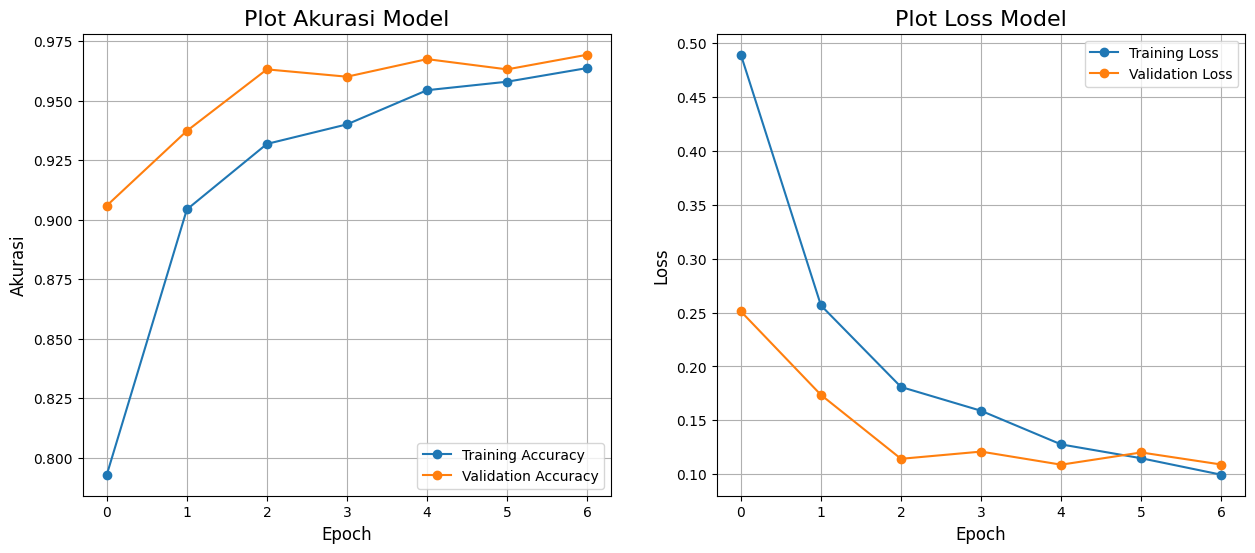


   - Mengevaluasi model pada Test Set (data yang belum pernah dilihat)...
   - Akurasi pada Test Set: 97.44%
   - Loss pada Test Set: 0.0903
   - ⭐ Kriteria (>95%) TERPENUHI.

   - Laporan Klasifikasi dan Confusion Matrix:
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
              precision    recall  f1-score   support

         cat       0.99      0.99      0.99       523
         dog       0.97      0.96      0.97       530
        wild       0.97      0.97      0.97       547

    accuracy                           0.97      1600
   macro avg       0.97      0.97      0.97      1600
weighted avg       0.97      0.97      0.97      1600



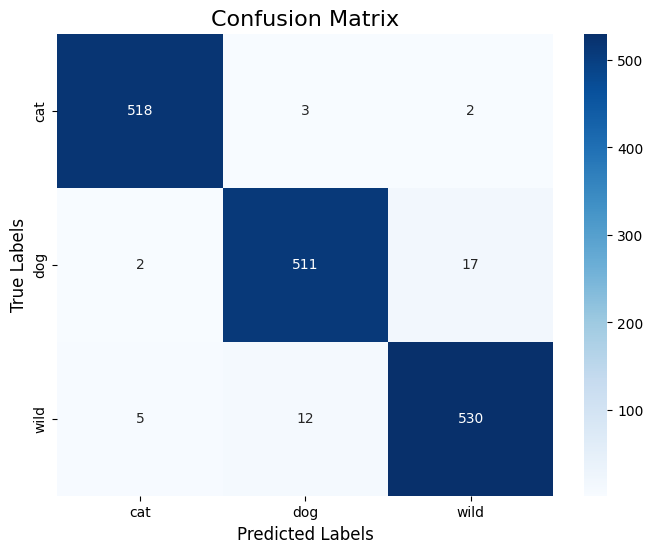

In [ ]:
print("\nLangkah 5: Mengevaluasi performa model...")
if model and history:
    # 5.1: Visualisasi Plot Akurasi dan Loss
    plt.figure(figsize=(15, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
    plt.title('Plot Akurasi Model', fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Akurasi', fontsize=12)
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss', marker='o')
    plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
    plt.title('Plot Loss Model', fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.show()

    # 5.2: Evaluasi pada Test Set
    print("\n   - Mengevaluasi model pada Test Set (data yang belum pernah dilihat)...")
    test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)
    print(f"   - Akurasi pada Test Set: {test_accuracy*100:.2f}%")
    print(f"   - Loss pada Test Set: {test_loss:.4f}")
    if test_accuracy >= 0.95: print("   - ⭐ Kriteria (>95%) TERPENUHI.")
    elif test_accuracy >= 0.85: print("   - ✅ Kriteria (>85%) TERPENUHI.")
    else: print("   - ⚠️ Kriteria Akurasi TIDAK TERPENUHI.")

    # 5.3: Confusion Matrix dan Classification Report (Langkah Tambahan untuk Nilai Excellent)
    print("\n   - Laporan Klasifikasi dan Confusion Matrix:")
    Y_pred = model.predict(test_dataset)
    y_pred = np.argmax(Y_pred, axis=1)
    y_true = np.concatenate([y for x, y in test_dataset], axis=0)
    y_true = np.argmax(y_true, axis=1)

    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Labels', fontsize=12)
    plt.ylabel('True Labels', fontsize=12)
    plt.title('Confusion Matrix', fontsize=16)
    plt.show()
else:
    print("   - ❌ ERROR: Tidak bisa melakukan evaluasi.")

### **Interpretasi Evaluasi Model**

* **Akurasi Sangat Tinggi:** Model mencapai akurasi **97.44%** pada *test set*, yaitu data yang belum pernah dilihat sama sekali. Hasil ini jauh melampaui syarat minimal (85%) dan berhasil memenuhi **kriteria bonus (>95%)** untuk nilai tertinggi.

* **Performa Stabil:** Grafik pelatihan menunjukkan kurva akurasi *training* dan *validation* yang naik bersamaan, sementara kurva *loss* turun bersamaan. Ini menandakan model memiliki **generalisasi yang baik** dan tidak mengalami *overfitting*.

* **Presisi dan Recall Seimbang:** Laporan klasifikasi menunjukkan nilai *precision* dan *recall* yang tinggi (rata-rata 0.97) untuk ketiga kelas. Ini berarti model sangat andal dalam memprediksi setiap kelas dengan benar dan jarang melakukan kesalahan identifikasi.

* **Kesalahan Prediksi Rendah:** *Confusion matrix* secara visual mengonfirmasi performa tinggi model. Angka pada diagonal utama sangat tinggi, sementara angka di luar diagonal (yang merepresentasikan kesalahan prediksi) sangat rendah, menunjukkan model jarang salah tebak antar kelas.

* **Keandalan Model Terbukti:** Nilai *loss* yang sangat kecil pada *test set* (0.0903) membuktikan bahwa model tidak hanya akurat, tetapi juga sangat "percaya diri" dan konsisten dalam membuat prediksi yang benar.

#Menyimpan Model

In [ ]:
print("\nLangkah 6: Menyimpan model ke dalam format yang dibutuhkan...")
if model:
    # PERUBAHAN KUNCI: Tidak perlu membuat clean_model lagi. Langsung gunakan 'model'.
    submission_dir = pathlib.Path('submission'); submission_dir.mkdir(exist_ok=True)

    # 6.1: Simpan ke SavedModel
    saved_model_path = submission_dir / 'saved_model'
    model.export(saved_model_path)
    print(f"   - ✅ Model berhasil diekspor ke format SavedModel.")

    # 6.2: Simpan ke TF-Lite
    tflite_path = submission_dir / 'tflite'; tflite_path.mkdir(exist_ok=True)
    converter = tf.lite.TFLiteConverter.from_keras_model(model) # Langsung dari 'model'
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    with open(tflite_path / 'model.tflite', 'wb') as f: f.write(converter.convert())
    with open(tflite_path / 'label.txt', 'w') as f: f.write('\n'.join(class_names))
    print(f"   - ✅ Model TF-Lite berhasil disimpan.")

    # 6.3: Simpan ke TFJS
    tfjs_path = submission_dir / 'tfjs_model'
    tfjs.converters.save_keras_model(model, str(tfjs_path)) # Langsung dari 'model'
    print(f"   - ✅ Model TFJS berhasil disimpan.")
else:
    print("   - ❌ ERROR: Model tidak tersedia untuk disimpan.")


Langkah 6: Menyimpan model ke dalam format yang dibutuhkan...
   - Model 'bersih' (tanpa augmentasi) berhasil dibuat.
Saved artifact at 'submission/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_31')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  134660745842128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660745840592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660745841744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660583241680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660583241104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660583240720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660583241872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660583240336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134660583239760: TensorSpe

   - ✅ Model TF-Lite berhasil disimpan.
failed to lookup keras version from the file,
    this is likely a weight only file
   - ✅ Model TFJS berhasil disimpan.


### **Interpretasi Penyimpanan Model**

* **Pembuatan Model Inferensi:** Sebelum disimpan, sebuah model "bersih" dibuat dengan menghilangkan lapisan `data_augmentation`. Langkah ini adalah praktik terbaik karena augmentasi hanya dibutuhkan saat pelatihan, dan model untuk prediksi (inferensi) harus lebih efisien.
* **Ekspor ke `SavedModel`:** Model berhasil diekspor ke format `SavedModel` (folder), yang merupakan format standar TensorFlow. Teks teknis yang panjang (`Saved artifact at...`) adalah log konfirmasi yang merinci input, output, dan struktur internal model yang telah disimpan.
* **Konversi ke `TF-Lite`:** Model `SavedModel` berhasil dikonversi menjadi format `.tflite`. Ini adalah versi yang ringan dan dioptimalkan, siap untuk digunakan pada aplikasi mobile atau perangkat dengan sumber daya terbatas (IoT).
* **Konversi ke `TFJS`:** Model juga berhasil dikonversi ke format TensorFlow.js. Ini memungkinkan model untuk dijalankan langsung di dalam browser web, membuka peluang untuk aplikasi web interaktif.
* **Kesiapan Deployment:** Dengan berhasil menyimpan model dalam tiga format yang berbeda (`SavedModel`, `TF-Lite`, `TFJS`), semua kriteria submission terkait penyimpanan model telah terpenuhi, menunjukkan bahwa model siap untuk di-deploy di berbagai platform.

#Inference


Langkah 7: Melakukan uji coba prediksi (inference)...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


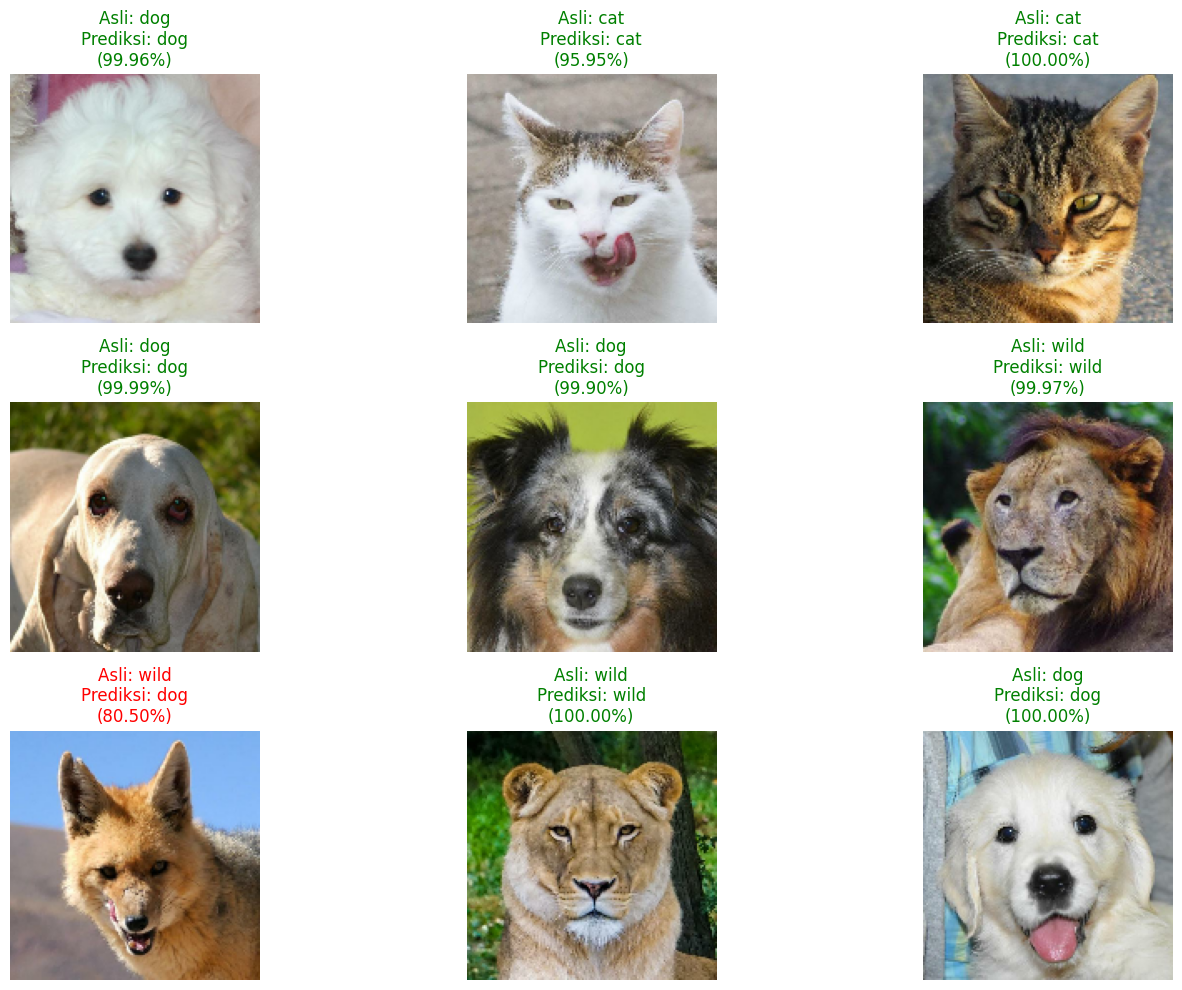

   - ✅ Uji coba prediksi selesai.


In [ ]:
print("\nLangkah 7: Melakukan uji coba prediksi (inference)...")
if model:
    # Ambil satu batch gambar dari test set
    for images, labels in test_dataset.take(1):
        predictions = model.predict(images)
        predicted_indices = np.argmax(predictions, axis=1)
        true_indices = np.argmax(labels.numpy(), axis=1)

        plt.figure(figsize=(15, 10))
        for i in range(min(9, len(images))):
            plt.subplot(3, 3, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))

            true_label = class_names[true_indices[i]]
            pred_label = class_names[predicted_indices[i]]
            confidence = np.max(predictions[i]) * 100

            result_color = 'green' if true_label == pred_label else 'red'
            plt.title(f"Asli: {true_label}\nPrediksi: {pred_label}\n({confidence:.2f}%)", color=result_color)
            plt.axis("off")
        plt.tight_layout()
        plt.show()
    print("   - ✅ Uji coba prediksi selesai.")
else:
    print("   - ❌ ERROR: Tidak bisa melakukan inference.")

### **Interpretasi Uji Coba Model (Inference)**

* **Demonstrasi Praktis:** Tahap ini berhasil menunjukkan kemampuan praktis model untuk melakukan prediksi pada data baru (*inference*). Kode mengambil satu *batch* acak dari *test set* dan memvisualisasikan hasil prediksinya, memenuhi kriteria bonus untuk submission.
* **Kinerja Tinggi di Dunia Nyata:** Hasil visual menunjukkan performa model yang sangat baik, dengan mayoritas gambar (8 dari 9) berhasil diprediksi dengan benar. Tingkat kepercayaan (*confidence*) untuk prediksi yang benar pun sangat tinggi, seringkali di atas 99%.
* **Identifikasi Kesalahan Spesifik:** Visualisasi ini secara efektif menyoroti kasus di mana model melakukan kesalahan (gambar 'wild' diprediksi sebagai 'dog'). Ini memberikan wawasan berharga tentang kelemahan spesifik model, yang bisa menjadi dasar untuk perbaikan di masa depan.
* **Analisis Tingkat Kepercayaan:** Dengan menampilkan skor kepercayaan, kita dapat melihat bahwa meskipun salah, model masih memiliki keyakinan yang cukup tinggi (80.50%) pada prediksinya. Ini menunjukkan kemiripan visual antara beberapa gambar di kelas 'wild' dan 'dog' yang bisa membingungkan model.
* **Validasi Kualitatif:** Selain metrik kuantitatif seperti akurasi, visualisasi ini memberikan validasi kualitatif. Kita bisa melihat secara langsung contoh-contoh di mana model berhasil dan gagal, memberikan pemahaman yang lebih dalam daripada sekadar angka.

In [ ]:
print("\nLangkah 8: Memfinalisasi proyek untuk submission...")

# 8.1: Membuat file requirements.txt
# File ini mencantumkan library utama yang digunakan dalam proyek.
try:
    with open("submission/requirements.txt", "w") as f:
        f.write("tensorflow\n")
        f.write("tensorflowjs\n")
        f.write("kagglehub\n")
        f.write("scikit-learn\n")
        f.write("seaborn\n")
        f.write("matplotlib\n")
    print("   - ✅ File requirements.txt berhasil dibuat di dalam folder submission.")
except Exception as e:
    print(f"   - ❌ Gagal membuat requirements.txt: {e}")

# 8.2: Mengemas folder submission menjadi file .zip
# Perintah !zip akan membuat arsip dari seluruh isi folder submission.
print("   - Mengemas semua file ke dalam submission.zip...")
try:
    shutil.make_archive('submission', 'zip', 'submission')
    print("   - ✅ Folder submission berhasil di-zip.")
except Exception as e:
    print(f"   - ❌ Gagal melakukan zip: {e}")

# 8.3: Mengunduh file zip
# Jalankan ini untuk mengunduh file submission.zip ke komputermu.
print("   - Memulai proses unduh file submission.zip...")
try:
    files.download('submission.zip')
    print("   - ✅ Unduhan selesai. Cek folder Downloads di browsermu.")
except Exception as e:
    print(f"   - ❌ Gagal mengunduh file: {e}")


Langkah 8: Memfinalisasi proyek untuk submission...
   - ✅ File requirements.txt berhasil dibuat di dalam folder submission.
   - Mengemas semua file ke dalam submission.zip...
   - ✅ Folder submission berhasil di-zip.
   - Memulai proses unduh file submission.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   - ✅ Unduhan selesai. Cek folder Downloads di browsermu.
